[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aranaur/aranaur.rbind.io/blob/main/lectures/genesis/sdb/labs/worked_example_uk.ipynb)

# Розібраний приклад: прогноз уваги до ChatGPT від початку до кінця

*School of Digital Business 5.0 — Часові ряди в епоху AI.*

Один продукт, уся процедура: **подивитися на дані → забектестити дев'ять прогнозистів → прочитати похибки,
горизонти й інтервали → скомбінувати → спрогнозувати → зробити висновки.** Ряд — щоденна кількість
переглядів статті про ChatGPT в англійській Вікіпедії, публічний індикатор уваги до AI-продукту.

Ноутбук збережено **з результатами**: його можна читати, нічого не запускаючи. Щоб перезапустити в Colab —
`Runtime → Run all`; під час першого запуску завантажуються три моделі (близько 1,5 ГБ), це кілька хвилин.

## 0. Налаштування

In [1]:
!pip install -q chronos-forecasting statsforecast timesfm tirex-ts

In [2]:
import os, time, warnings
os.environ["NIXTLA_ID_AS_COL"] = "true"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore")
import transformers
transformers.utils.logging.disable_progress_bar()
transformers.utils.logging.set_verbosity_error()
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, AutoETS, AutoTheta, MSTL, Naive, SeasonalNaive

plt.rcParams.update({"figure.figsize": (12, 3.6), "axes.grid": True, "grid.alpha": 0.3})
PINK, NAVY, TEAL, ORANGE, SLATE = "#e64173", "#181485", "#20B2AA", "#FFA500", "#314f4f"
CLASSICAL = {"Naive": lambda s: Naive(alias="Naive"),
             "Seasonal naive": lambda s: SeasonalNaive(s, alias="Seasonal naive"),
             "ETS": lambda s: AutoETS(season_length=s, alias="ETS"),
             "ARIMA": lambda s: AutoARIMA(season_length=s, alias="ARIMA"),
             "Theta": lambda s: AutoTheta(season_length=s, alias="Theta"),
             "MSTL": lambda s: MSTL(season_length=[s, 365], alias="MSTL")}
_loaded = {}


def foundation(name):
    # Load each foundation model once; the first call downloads its weights.
    if name not in _loaded:
        if name == "Chronos-2":
            from chronos import BaseChronosPipeline
            _loaded[name] = BaseChronosPipeline.from_pretrained("amazon/chronos-2", device_map="cpu")
        elif name == "TimesFM":
            import timesfm
            m = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")
            m.compile(timesfm.ForecastConfig(max_context=1024, max_horizon=128, normalize_inputs=True,
                                             use_continuous_quantile_head=True))
            _loaded[name] = m
        elif name == "TiRex":
            import tirex
            _loaded[name] = tirex.load_model("NX-AI/TiRex", device="cpu")
    return _loaded[name]


def forecast_fm(name, history, h):
    # Median and 80% interval (P10, P90) from a foundation model, for one series.
    ctx = torch.tensor(np.asarray(history, dtype=np.float32))
    model = foundation(name)
    if name == "Chronos-2":
        q, _ = model.predict_quantiles([ctx], prediction_length=h, quantile_levels=[0.1, 0.5, 0.9])
        q = np.asarray(q[0]).reshape(h, 3)
        return q[:, 1], q[:, 0], q[:, 2]
    if name == "TimesFM":
        point, q = model.forecast(horizon=h, inputs=[ctx.numpy()])
        q = np.asarray(q)[0]
        return np.asarray(point)[0], q[:, 1], q[:, 9]
    q, mean = model.forecast(context=[ctx], prediction_length=h)
    q = np.asarray(q)[0]
    return np.asarray(mean)[0], q[:, 0], q[:, 8]


def backtest(y, h, windows, season, classical, foundations, freq="D"):
    # Rolling-origin backtest: `windows` cuts of `h` steps at the end of y. One row per date and cut.
    df = pd.DataFrame({"unique_id": "series", "ds": y.index, "y": y.values})
    timing = {}
    start = time.time()
    models = [CLASSICAL[name](season) for name in classical]
    res = StatsForecast(models=models, freq=freq).cross_validation(df=df, h=h, n_windows=windows,
                                                                   step_size=h, level=[80])
    for name in classical:
        timing[name] = (time.time() - start) / len(classical)
    for name in foundations:
        start, parts = time.time(), []
        for cut in sorted(res["cutoff"].unique()):
            mid, lo, hi = forecast_fm(name, y[y.index <= cut].values, h)
            parts.append(pd.DataFrame({"ds": res.loc[res["cutoff"] == cut, "ds"].values, "cutoff": cut,
                                       name: mid, f"{name}-lo-80": lo, f"{name}-hi-80": hi}))
        res = res.merge(pd.concat(parts), on=["ds", "cutoff"])
        timing[name] = time.time() - start
    res["h"] = res.groupby("cutoff").cumcount() + 1
    return res, timing


def score(res, y, season, names, timing=None):
    # MASE (scaled by the seasonal-naive error in the year before the test), MAPE, bias, 80% coverage.
    past = y[y.index <= res["cutoff"].min()].values[-365:]
    scale = np.mean(np.abs(past[season:] - past[:-season]))
    rows = {}
    for name in names:
        e = res["y"] - res[name]
        row = {"MASE": np.mean(np.abs(e)) / scale, "MAPE, %": 100 * np.mean(np.abs(e) / res["y"]),
               "bias, %": 100 * np.mean(-e / res["y"])}
        if f"{name}-lo-80" in res:
            row["inside P10-P90"] = np.mean((res["y"] >= res[f"{name}-lo-80"]) & (res["y"] <= res[f"{name}-hi-80"]))
        if timing and name in timing:
            row["seconds"] = timing[name]
        rows[name] = row
    return pd.DataFrame(rows).T, scale

## 1. Спершу подивитися на дані

Три питання до будь-якої моделі: чи є **тренд**, **тижневий** ритм, **річна** сезонність?

1420 2022-12-05 2026-10-24


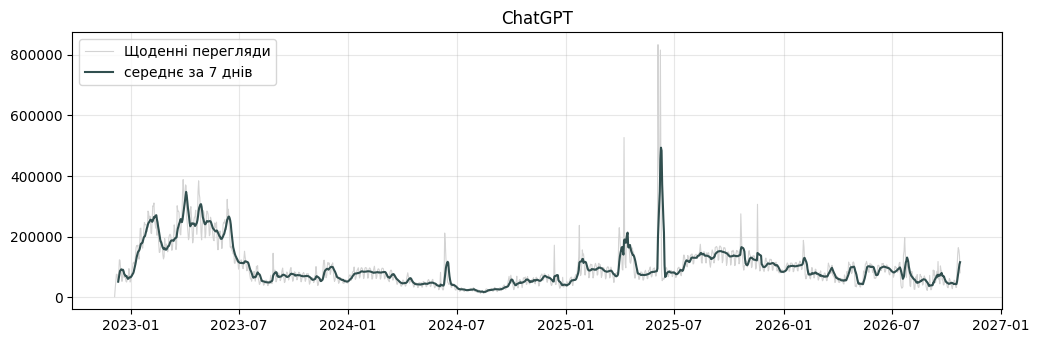

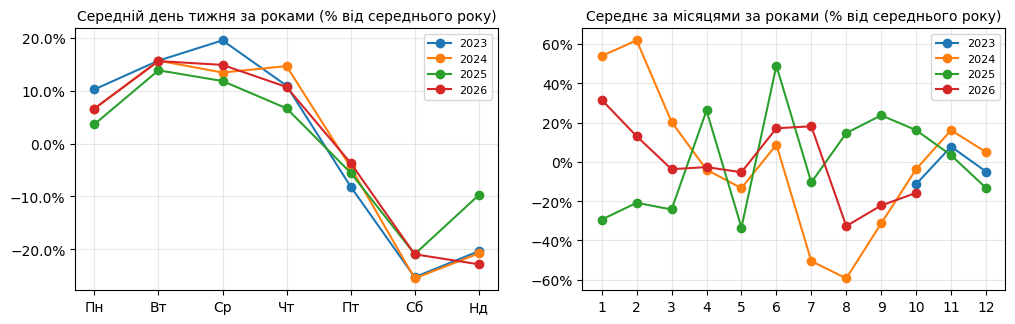

In [3]:
data = pd.read_csv("https://raw.githubusercontent.com/Aranaur/aranaur.rbind.io/main/lectures/genesis/sdb/data/pageviews.csv", parse_dates=["ds"])
y = data[data["unique_id"] == "ChatGPT"].set_index("ds")["y"].asfreq("D")
print(len(y), y.index.min().date(), y.index.max().date())

fig, ax = plt.subplots()
ax.plot(y.index, y.values, color="lightgray", lw=0.8, label="Щоденні перегляди")
ax.plot(y.index, y.rolling(7).mean(), color=SLATE, lw=1.5, label="середнє за 7 днів")
ax.legend(loc="upper left"); ax.set_title('ChatGPT'); plt.show()

recent = y[y.index >= y.index.max() - pd.Timedelta(days=3 * 365)]
rel = recent / recent.groupby(recent.index.year).transform("mean") - 1
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for year, g in rel.groupby(rel.index.year):
    axes[0].plot(range(7), g.groupby(g.index.dayofweek).mean().reindex(range(7)).values, "o-", label=str(year))
    axes[1].plot(range(1, 13), g.groupby(g.index.month).mean().reindex(range(1, 13)).values, "o-", label=str(year))
axes[0].set_xticks(range(7), ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Нд']); axes[0].set_title("Середній день тижня за роками (% від середнього року)", fontsize=10)
axes[1].set_xticks(range(1, 13)); axes[1].set_title("Середнє за місяцями за роками (% від середнього року)", fontsize=10)
for ax in axes:
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0)); ax.legend(fontsize=8)
plt.show()

**Що кажуть графіки**

- **Тижневий ритм:** вівторок–середа приблизно на 15% вищі за середній день року, субота — на 20–25% нижча;
  форма та сама щороку — ритм роботи й навчання.
- **Річна сезонність — але нестабільна:** глибокі літні провали у 2024 і 2026 роках (липень–серпень,
  канікули), а у 2025-му — жодного, бо домінував червневий сплеск.
- **Рівень:** хвилі, а не тренд — зростання протягом 2025 року, повільний спад у 2026-му і стрибок в
  останній тиждень даних.

Отже, хороший прогнозист має відтворити тиждень, не надто покладатися на річну форму, яка змінюється, і не
продовжувати тренд, якого немає.

## 2. Бектест

**Шість вікон по 28 днів**, травень–жовтень 2026, кожне прогнозується лише з днів до нього — і всі вони
після релізу кожної foundation model з тесту. Дев'ять прогнозистів:

| Класичні (підганяються під цей ряд) | Foundation models (без підгонки) |
|---|---|
| Наївний · Сезонний наївний · ETS · ARIMA · Theta · MSTL (тиждень + рік) | Chronos-2 · TimesFM 2.5 · TiRex |

Ця клітинка працює кілька хвилин — найдовше рахуються ARIMA і завантаження трьох моделей.

In [4]:
H, WINDOWS, SEASON = 28, 6, 7
CLASSICAL_MODELS = ["Naive", "Seasonal naive", "ETS", "ARIMA", "Theta", "MSTL"]
FOUNDATION = ["Chronos-2", "TimesFM", "TiRex"]
res, timing = backtest(y, H, WINDOWS, SEASON, CLASSICAL_MODELS, FOUNDATION)
NAMES = CLASSICAL_MODELS + FOUNDATION
print("cut-offs:", [f"{c:%Y-%m-%d}" for c in sorted(res["cutoff"].unique())])

cut-offs: ['2026-05-09', '2026-06-06', '2026-07-04', '2026-08-01', '2026-08-29', '2026-09-26']


## 3. Таблиця результатів

**MASE** менше 1 — краще за «як тиждень тому» (як воно було в рік до тесту). **Зміщення** — середнє
завищення (+) чи заниження (−). **Inside P10–P90** має бути близько 80%.

In [5]:
board, scale = score(res, y, SEASON, NAMES, timing)
board.round(3).style.background_gradient(subset=["MASE"], cmap="RdYlGn_r").format(precision=3)

,MASE,"MAPE, %","bias, %",inside P10-P90,seconds
Naive,0.960,37.611,-26.958,1.000,10.771
Seasonal naive,0.881,40.205,5.203,1.000,10.771
ETS,0.781,32.193,-10.648,0.946,10.771
ARIMA,0.758,38.761,13.361,0.976,10.771
Theta,0.694,29.537,-6.613,1.000,10.771
MSTL,1.295,49.961,-21.772,0.863,10.771
Chronos-2,0.742,31.279,-5.275,0.690,3.195
TimesFM,0.766,31.062,-9.463,0.732,2.253
TiRex,0.662,29.795,2.436,0.768,3.375


**Що каже таблиця**

- **Найкраща модель на цьому ряді — не найкраща в середньому.** На десяти продуктах лекції лідирувала
  Chronos-2; тут попереду **TiRex і Theta** — класичний метод 2000 року.
- **MSTL** з річною сезонністю — найгірший: чотирьох років історії замало, щоб оцінити річну форму, яка ще й
  змінюється.
- Остання колонка: класичні інтервали **занадто широкі** (майже всі дні всередині), інтервали foundation
  models — **занадто вузькі** (близько 70–77%). З коробки не відкалібровані ні ті, ні інші.

## 4. Похибки за горизонтом і за вікнами

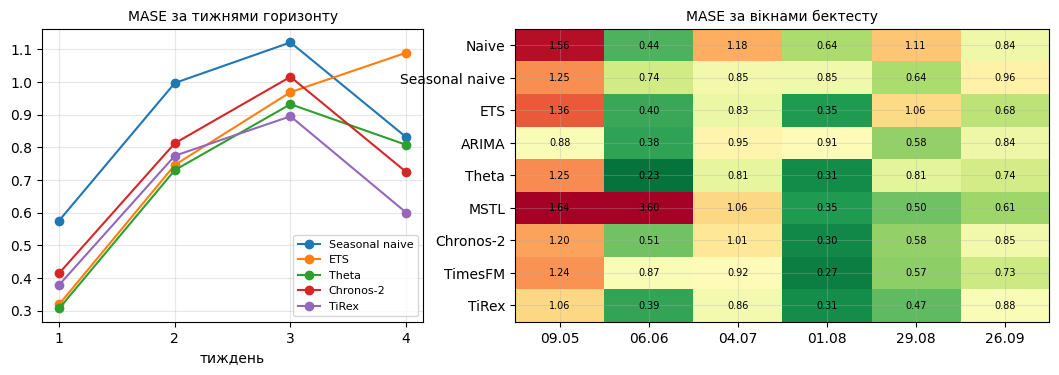

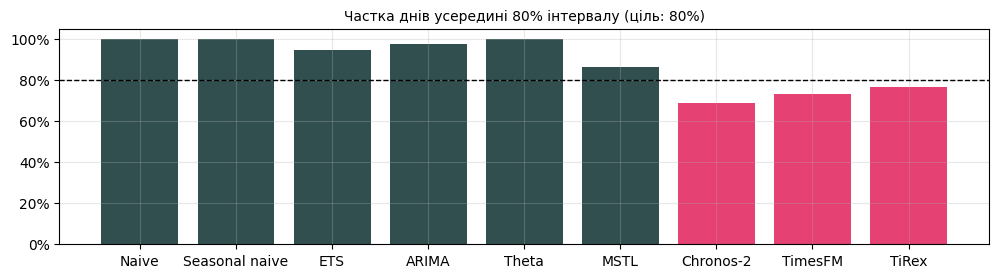

In [6]:
SHOW = ['Seasonal naive', 'ETS', 'Theta', 'Chronos-2', 'TiRex']

by_h = res.groupby((res["h"] - 1) // 7).apply(
    lambda g: pd.Series({m: np.mean(np.abs(g["y"] - g[m])) / scale for m in SHOW}), include_groups=False)
by_w = res.groupby("cutoff").apply(
    lambda g: pd.Series({m: np.mean(np.abs(g["y"] - g[m])) / scale for m in NAMES}), include_groups=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), width_ratios=[1, 1.4])
for m in SHOW:
    axes[0].plot(by_h.index + 1, by_h[m], "o-", label=m)
axes[0].set_xticks(by_h.index + 1); axes[0].set_xlabel("тиждень"); axes[0].set_title("MASE за тижнями горизонту", fontsize=10)
axes[0].legend(fontsize=8)
im = axes[1].imshow(by_w.T.values, cmap="RdYlGn_r", vmin=0.2, vmax=1.6, aspect="auto")
axes[1].set_yticks(range(len(NAMES)), NAMES); axes[1].set_xticks(range(len(by_w)), [f"{c:%d.%m}" for c in by_w.index])
for i in range(len(NAMES)):
    for j in range(len(by_w)):
        axes[1].text(j, i, f"{by_w.iloc[j, i]:.2f}", ha="center", va="center", fontsize=7)
axes[1].set_title("MASE за вікнами бектесту", fontsize=10)
plt.show()

covered = board["inside P10-P90"].dropna()
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.bar(covered.index, covered.values, color=[PINK if m in FOUNDATION else SLATE for m in covered.index])
ax.axhline(0.8, color="black", lw=1, ls="--")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0)); ax.set_ylim(0, 1.05)
ax.set_title("Частка днів усередині 80% інтервалу (ціль: 80%)", fontsize=10); plt.show()

- **Перший тиждень — найлегший:** його похибка приблизно вдвічі менша, ніж у тижнях 2–4. Перепрогнозуйте
  щотижня, а не довіряйте чотиритижневому прогнозу до кінця.
- **Вікна відрізняються сильніше, ніж моделі.** У кожної моделі є погані вікна (травень) і хороші
  (серпень). Одне вікно розповіло б іншу історію — тому їх шість.

## 5. Комбінація, обрана заздалегідь

Тиждень 8 будь-якого курсу прогнозування: **середнє** моделей рідко найкраще і майже ніколи не погане.
Фіксуємо пару **до** того, як дивимося на результати — одна класична модель, одна foundation model: ETS + Chronos-2.

In [7]:
res["ETS + Chronos-2"] = res[["ETS", "Chronos-2"]].mean(axis=1)
combo_board, _ = score(res, y, SEASON, ["ETS", "Chronos-2", "ETS + Chronos-2"])
combo_board[["MASE", "MAPE, %"]].round(3)

,MASE,"MAPE, %"
ETS,0.781,32.193
Chronos-2,0.742,31.279
ETS + Chronos-2,0.686,28.537


Середнє обіграє **обидві** свої складові. Це не найкраща окрема модель — але обирати найкращу окрему модель за
її результатом на тесті і є тією помилкою, від якої бектест захищає.

## 6. Прогноз на наступні чотири тижні

З усієї історії до 24 жовтня 2026: Chronos-2 з діапазоном і середнє ETS + Chronos-2. В останній тиждень
ряд стрибнув угору; обидва прогнози стартують високо й повертаються до звичного тижневого патерну. Чи
стрибок збережеться — саме про це говорить ширина діапазону.

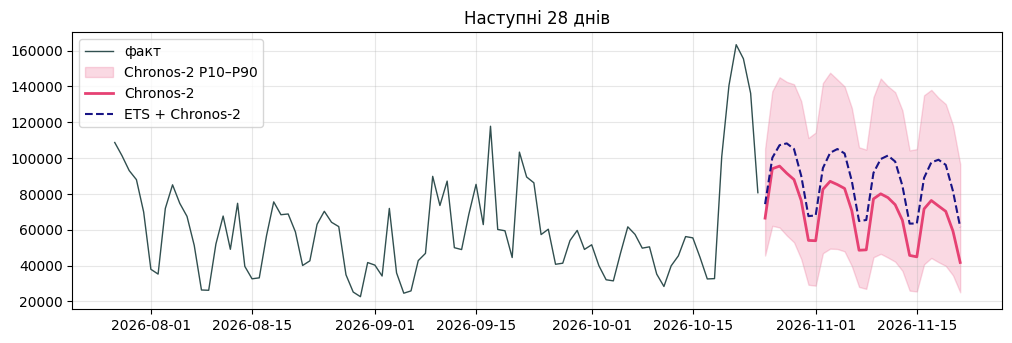

,P10,P50,P90,ETS + Chronos-2
2026-10-25,45582.0,66463.0,105167.0,74281.0
2026-10-26,62170.0,94047.0,137313.0,100160.0
2026-10-27,61233.0,95525.0,145123.0,107202.0
2026-10-28,56765.0,91515.0,142559.0,108205.0
2026-10-29,52986.0,87993.0,141211.0,105076.0
2026-10-30,43615.0,76290.0,131828.0,90061.0
2026-10-31,29257.0,54017.0,111207.0,67589.0
2026-11-01,28743.0,53848.0,114271.0,67974.0
2026-11-02,46873.0,82543.0,141905.0,94409.0
2026-11-03,49421.0,87021.0,147661.0,102949.0


In [8]:
mid, lo, hi = forecast_fm("Chronos-2", y.values, H)
ets = StatsForecast(models=[AutoETS(season_length=SEASON)], freq="D").forecast(
    df=pd.DataFrame({"unique_id": "s", "ds": y.index, "y": y.values}), h=H)["AutoETS"].values
future = pd.date_range(y.index[-1] + pd.Timedelta(days=1), periods=H)
fig, ax = plt.subplots()
ax.plot(y.index[-90:], y.values[-90:], color=SLATE, lw=1, label="факт")
ax.fill_between(future, lo, hi, color=PINK, alpha=0.2, label="Chronos-2 P10–P90")
ax.plot(future, mid, color=PINK, lw=2, label="Chronos-2")
ax.plot(future, (mid + ets) / 2, "--", color=NAVY, lw=1.5, label="ETS + Chronos-2")
ax.legend(loc="upper left"); ax.set_title("Наступні 28 днів"); plt.show()
pd.DataFrame({"P10": lo, "P50": mid, "P90": hi, "ETS + Chronos-2": (mid + ets) / 2}, index=future).round(0).head(14)

## 7. Висновки

1. **Бектестуйте на власному ряді.** Модель, що виграє в середньому (Chronos-2), тут у середині таблиці;
   метод 2000 року (Theta) — серед лідерів. Рейтинги не переносяться.
2. **Бенчмарки важливі.** Шість із восьми моделей обіграли «як тиждень тому» — але ненабагато, а MSTL не
   обіграв зовсім.
3. **Плануйте з урахуванням горизонту.** Перший тиждень приблизно вдвічі точніший за тижні 2–4:
   оновлюйте прогноз щотижня.
4. **Перевірте діапазон, перш ніж ним користуватися.** Класичні інтервали тут занадто широкі, інтервали
   foundation models — занадто вузькі. Розширюйте чи звужуйте їх за тим, що показав бектест.
5. **Комбінуйте.** Заздалегідь обране середнє класичної та foundation model обіграло обидві — найдешевша
   страховка в прогнозуванні.